# 07 基于线性判别分析的分类预测

> **模块**：多元分析 ｜ **数据**：`data.xlsx` ｜ **依赖**：numpy、pandas、scikit-learn

## 1. 问题背景

判别分析是一种分类方法，它是根据已掌握的每个类别的若干样本的数据信息，求出判别函数，再根据判别函数判别位置样本点所属的类别。在医学研究中经常遇到这类问题，例如，临床上常需根据就诊者的各项症状、体征、实验室检查、病例学检查及医学影像学资料等对其作出是否有某种疾病的诊断或对几种可能患有的疾病进行鉴别诊断，有时已初步诊断为某种疾病，还需进一步作出属该类疾病中哪一种或哪一型的判断。


## 2. 学习目标

- 掌握 Fisher 线性判别分析的思路
- 掌握 Fisher 线性判别分析的一般步骤
- 掌握基于 sklearn 实现 LDA 判别分析


## 3. 环境与数据

- Jupyter 开发环境
- Python 3.10


## 4. 方法与实现

### 4.1 判别分析

定义1. 判别分析先根据已知类别的实物的性质（自变量），建立函数式（自变量的线性组合，即判别函数），然后对未知类别的新事物进行判断以将之归入已知的类别中。

判别分析主要分为费希尔（Fisher）判别、贝叶斯（Bayes)判别和距离判别三大类。
- **1. 距离判别**

距离判别的基本思想是按就近原则进行归类。首先根据已知分类的数据分别计算各类的中心，即各类的均值，若任一新样本的观测值都与第i类的中心距离最近，就认为它属于第i类。这个距离常用的有马氏距离和欧式距离。

- **2. 贝叶斯判别**

贝叶斯判别就是根据已知的先验信息$P(A|B)$，利用贝叶斯公式：

$$
P(B|A) = \frac{P(A|B) \cdot P(B)}{P(A)}

$$

求出后验概率$P(B|A)$，即该样本属于某一类的概率，然后选择具有最大后验概率的类作为该样本的所属类。

- **3. 费希尔判别**

该判别算法主要包含线性判别分析（Linear Discriminant Analysis，简称LDA）和二次判别分析（Quadratic Discriminant Analysis，简称QDA）。中心思想就是“投影”，就是将高维空间的点向低维空间投影，从而简化问题，进行分类。

> *原稿配图未随 notebook 保存，此处暂缺。*

### 4.2 Fisher 线性判别分析（LDA）

Fisher线性判别也叫作LDA，它可用于降维也可用于分类，当维度降低成一维时，确定一个阈值，即可实现分类。

#### 4.2.1 基本思想

Fisher的基本思想是：**类内小，类间大**。

也就是说，我们要让属于同一类的样本映射到某一条直线上后的距离越小越好，而不同类样本之间的距离要越大越好。所以我们需要训练这样一条直线，把p维的样本数据都投影到一个一维的方向，使得不同的样本在降维后的一维空间内具有“类内小，类间大”的结果，从而很好地将两类数据分开。

> *原稿配图未随 notebook 保存，此处暂缺。*

如上图为LDA的二维示意图。“+”、“-”分别代表正例和反例，椭圆表示数据簇的外轮廓，虚线表示投影，红色实心圆和实心三角形分别表示两类样本投影后的中心点。

针对二分类数据，求解最佳投影方向$w^*$的一般步骤为：

1. 将两类的训练样本集（总个数为$n$）划分为两个子集$D_1$和$D_2$。
2. 计算各类的均值向量。

$\mu_1 = \frac{1}{N_1}\sum_{x_i∈D_1}{x_i}$

$\mu_2 = \frac{1}{N_2}\sum_{x_i∈D_2}{x_i}$

3. 计算各类的类内离散度矩阵$S_1$、$S_2$和总样本类内离散度矩阵$S_w$。

$S_1 = \sum_{x_i∈D_1}{(x_i-\mu_1){(x_i-\mu_1)^T}}$

$S_2 = \sum_{x_i∈D_2}{(x_i-\mu_2){(x_i-\mu_2)^T}}$

$S_w = S_1 + S_2$

4. 计算样本类间离散度矩阵$S_b$。

$S_b = (\mu_1-\mu_2){(\mu_1-\mu_2)^T}$

5. 计算矩阵$S_w$的逆矩阵$S_w^{-1}$和矩阵$S_w^{-1}S_b$。
6. 计算矩阵$S_w^{-1}S_b$的最大特征值对应的特征向量$p$，当为二分类样本时，$p = \mu_1-\mu_2$。
7. 投影向量

$w^* = S_w^{-1}p = S_w^{-1}(\mu_1-\mu_2)$

最后通过$y = w^{*T}x$对样本集合做线性变换得到$n$个样本投影后的样本值$y_1,y_2,...,y_n$，对这些投影之后的样本值进行分类，确定一个阈值$w_0$。

$w_0$取值常用以下两种方法：

- （1）：$w_0 = \frac{w^{*T}\mu_1+w^{*T}\mu_2}{2}$
- （2）：$w_0 = \frac{N_1w^{*T}\mu_1+N_2w^{*T}\mu_2}{N_1+N_2}$

（其中$N_1$、$N_2$为子集$D_1$、$D_2$的样本个数，且$N_1+N_2=n$）

对待分类样本$X$进行分类：

- 如果$y = w^{*T}X>w_0$，则$X∈第一类$。
- 如果$y = w^{*T}X<w_0$，则$X∈第二类$。

#### 4.2.2 蠓虫分类

（1989年国际大学生数学建模竞赛A题：蠓虫分类）蠓虫是一种昆虫，分为很多类型，其中有一种名为Af，是能传播花粉的益虫；另一种名为Apf，是会传播疾病的害虫。这两种类型的蠓虫在形态上十分相似，很难区别。现测得9只Af和6只Apf蠓虫的触角长度和翅膀长度数据。

$
Af：(1.24, 1.72)，(1.36, 1.74)，(1.38, 1.64)，(1.38, 1.82)，(1.38, 1.90)，
(1.40, 1.70)，(1.48, 1.82)，(1.54, 1.82)，(1.56, 2.08)；
$

$
Apf：(1.14, 1.78)，(1.18, 1.96)，(1.20, 1.86)，(1.26, 2.00)，(1.28, 2.00)，(1.30, 1.96)
$

若两类蠓虫协方差矩阵相等，试判别(1.24, 1.80)，(1.28, 1.84)与(1.40, 2.04)三只蠓虫属于哪一类。

**因为上例分类任务所有的类别都使用相同的协方差矩阵$Σ$，那么我们使用LDA来预测未知样本的分类。反之，如果分类任务不同的类别使用不同的协方差矩阵$Σ_k$，那么就是使用QDA来预测未知样本的分类。**

##### 4.2.2.1 计算过程


In [1]:
import numpy as np
import pandas as pd
# 1.构建数据，输入已知样本数据
data = pd.DataFrame([[1.24,1.72], [1.36,1.74], [1.38,1.64], [1.38,1.82], [1.38,1.90], [1.40,1.70],
    [1.48,1.82], [1.54,1.82], [1.56,2.08], [1.14,1.78], [1.18,1.96], [1.20,1.86],
    [1.26,2.00], [1.28,2.00], [1.30,1.96]],columns = ['触角长度','翅膀长度'])
# 添加target列，1表示Af蠓虫，2表示Apf蠓虫
data['target']=np.hstack([np.ones(9),2*np.ones(6)])
data

,触角长度,翅膀长度,target
0,1.24,1.72,1.0
1,1.36,1.74,1.0
2,1.38,1.64,1.0
3,1.38,1.82,1.0
4,1.38,1.90,1.0
5,1.40,1.70,1.0
6,1.48,1.82,1.0
7,1.54,1.82,1.0
8,1.56,2.08,1.0
9,1.14,1.78,2.0


In [2]:
# 2.将数据按照标签拆分，并且只取前两列，得到就是两类的子集D1,D2
df1 = data[data["target"]==1]
df2 = data[data["target"]==2]
df1 = df1.iloc[:,:2]
df2 = df2.iloc[:,:2]  
print(df1,'\n',df2)

   触角长度  翅膀长度
0  1.24  1.72
1  1.36  1.74
2  1.38  1.64
3  1.38  1.82
4  1.38  1.90
5  1.40  1.70
6  1.48  1.82
7  1.54  1.82
8  1.56  2.08 
     触角长度  翅膀长度
9   1.14  1.78
10  1.18  1.96
11  1.20  1.86
12  1.26  2.00
13  1.28  2.00
14  1.30  1.96


In [3]:
# 3.计算各类的均值向量
df1_mean = np.matrix(df1.mean())
df2_mean = np.matrix(df2.mean())
df1 = np.matrix(df1)
df2 = np.matrix(df2)
print(df1_mean,'\n',df2_mean)

[[1.41333333 1.80444444]] 
 [[1.22666667 1.92666667]]


In [4]:
# 4.计算各类的类内离散度矩阵S1、S2和总样本类内离散度矩阵Sw
# 先计算两类样本个数
N1 = df1.shape[0]
N2 = df2.shape[0]
# 先创建两个全0的2×2矩阵作为初始矩阵
# 使用for循环每个样本计算得到最终S1、S2、Sw
S1 = np.zeros((2,2))
for i in range(0,N1):
    a = (df1[i]-df1_mean).reshape(2,1)
    S1 = S1+np.dot(a,a.T)
S2 = np.zeros((2,2))
for i in range(0,N2):
    a = (df2[i]-df2_mean).reshape(2,1)
    S2 = S2+np.dot(a,a.T)
Sw = S1+S2
print('总样本类内离散度矩阵Sw(2×2)\n',Sw)

总样本类内离散度矩阵Sw(2×2)
 [[0.09813333 0.0864    ]
 [0.0864     0.17395556]]


In [5]:
# 5.计算样本类间离散度矩阵Sb
p = (df1_mean-df2_mean).reshape(2,1)
Sb = p*p.T
print('样本类间离散度矩阵Sb(2×2)\n',Sb)

样本类间离散度矩阵Sb(2×2)
 [[ 0.03484444 -0.02281481]
 [-0.02281481  0.01493827]]


In [6]:
# 6.计算矩阵Sw的逆矩阵 S−1w和矩阵 S−1w*Sb
# 先求Sw的逆矩阵
Sw_inv = Sw**(-1) 
# 求S−1w*Sb的特征值和特征向量
A1,A2 = np.linalg.eig(Sw_inv*Sb)
print('特征值为：',A1,'\n','特征向量为：\n',A2)

特征值为： [ 1.19403208e+00 -5.55111512e-17] 
 特征向量为：
 [[ 0.83709469  0.54778594]
 [-0.54705802  0.83661853]]


In [7]:
# 7.求最佳投影方向w∗

# 方法一：矩阵S−1w*Sb最大特征值对应的特征向量
# 第一个特征值对应的特征向量（A2第一列）
w1 = A2[:,0]


# 方法二：对于二分类样本w∗ = S−1w*(μ1-μ2)
w2 = Sw_inv*p

w1[0]/w1[1]==w2[0]/w2[1]

matrix([[ True]])

两种方法得到的投影向量$w^*$数据不完全相同，但是比值相同，得到的结果相同，只是向量相乘的倍数不同。（求特征向量得到的向量是单位向量）

In [8]:
# 得到最终通过y = w∗T x对样本做线性变化投影头的样本值y1，y2
y1 = w1.T*df1.T
y2 = w1.T*df2.T
# 确定阈值w0
w0 = (y1.mean()+y2.mean())/2
print('阈值w0为：',w0)
# 输入待判样本点数据
x0 = np.matrix([[1.24,1.80], [1.28,1.84], [1.40,2.04]])
# 根据w∗得到投影后的值
res = np.dot(w1.T,x0.T)
res = res.tolist()[0]
# 对每个值循环与wo比较后分类
for i in range(x0.shape[0]):
    if res[i]>w0:
        print('测试样本',i+1,'属于Af蠓虫！')
    else:
        print('测试样本',i+1,'属于Apf蠓虫！')

阈值w0为： 0.08439785121670215
测试样本 1 属于Apf蠓虫！
测试样本 2 属于Apf蠓虫！
测试样本 3 属于Apf蠓虫！


##### 4.2.2.2 sklearn 求解

使用scikit-learn库中的LinearDiscriminantAnalysis类可以实现LDA判别

`sklearn.discriminant_analysis.LinearDiscriminantAnalysis(solver=’svd’, shrinkage=None, priors=None, n_components=None, store_covariance=False, tol=0.0001)`
- solver：指定了求解最优化问题的算法，可以为如下的值。

$\quad$ $\quad$'svd'：奇异值分解。对于有大规模特征的数据，推荐用这种算法。

$\quad$ $\quad$'lsqr'：最小平方差，可以结合skrinkage参数。

$\quad$ $\quad$'eigen' ：特征分解算法，可以结合shrinkage参数。

- skrinkage：接收‘auto’或者‘float’。该参数通常在训练样本数量小于特征数量的场合下使用。该参数只有在solver=lsqr或者eigen下才有意义。'字符串‘auto’：根据Ledoit-Wolf引理来自动决定shrinkage参数的大小。'None'：不使用shrinkage参数。'float'（位于0~1之间）：指定shrinkage参数。
- priors：接收array，数组中的元素依次指定了每个类别的先验概率。如果为No，则认为每个类的先验概率都是等可能的。
- n_components：接收int。指定了数组降维后的维度（该值必须小于n_classes-1）。
- store_covariance：接收布尔值。如果为True，则需要额外计算每个类别的协方差矩阵。
- warm_start：接收布尔值。如果为True，那么使用前一次训练结果继续训练，否则从头开始训练。
- tol：一个浮点数。它指定了用于SVD算法中评判迭代收敛的阈值。

In [10]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
# 定义一个LDA分类器对象
model = LDA()
# 提取特征数据和目标分类数据
x = data.iloc[:,:2].values
y = data.iloc[:,2].values
# 训练模型
model.fit(x, y)
# 待分类样本预测
# 将 x0 转换为 numpy 数组
y_pre = model.predict(np.asarray(x0))
print("三个样本判别结果为：",y_pre)
print("已知样本的误判率为：",1-model.score(x, y))

三个样本判别结果为： [2. 2. 2.]
已知样本的误判率为： 0.0


#### 4.2.3 健康状态分类

从健康人群、硬化症患者和冠心病患者中分别随机选取10人、6人和4人，考察了他们各自心电图的5个不同指标（记作）如下表所示，试对两个待判样品作出判断。

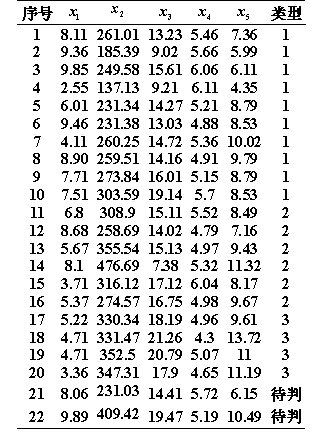

以上数据保存在 `../data/disease_data.xlsx` 文件中。

In [11]:
# 导入数据
data=pd.read_excel("../data/disease_data.xlsx",header=None,index_col = 0)
data

,1,2,3,4,5,6
0,,,,,,
序号,x1,x2,x3,x4,x5,类型
1,8.11,261.01,13.23,5.46,7.36,1
2,9.36,185.39,9.02,5.66,5.99,1
3,9.85,249.58,15.61,6.06,6.11,1
4,2.55,137.13,9.21,6.11,4.35,1
5,6.01,231.34,14.27,5.21,8.79,1
6,9.46,231.38,13.03,4.88,8.53,1
7,4.11,260.25,14.72,5.36,10.02,1
8,8.9,259.51,14.16,4.91,9.79,1


In [14]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.model_selection import cross_val_score

df = data.values
df = df[1:]                                   # ← 去掉表头行

x1 = df[:-2, :-1].astype(float)
y1 = df[:-2, -1].astype(int)
x_pre = df[-2:, :-1].astype(float)            # ← 加 astype(float)

clf = LDA()
clf.fit(x1, y1)
print("判别结果为：", clf.predict(x_pre))
print("已知样本误判率：", 1 - clf.score(x1, y1))
print("交叉验证准确率：", cross_val_score(clf, x1, y1, cv=2))

判别结果为： [1 2]
已知样本误判率： 0.0
交叉验证准确率： [0.9 0.8]


### 4.3 马氏距离判别与 Fisher 判别

> 来源：教材参考实现《数学建模算法与应用》10.4 节的练习稿（MIT，Zhanghan Wang），代码保持原样，仅按需改写数据路径并清空输出。

[判别分析和聚类分析的区别](https://www.sohu.com/a/146609190_301099)
[线性判别分析优于PCA的地方](https://blog.csdn.net/liuweiyuxiang/article/details/78874106)

#### 1. 距离判别
- 马氏距离: $d(x, y) = \sqrt{(x-y)^T \Sigma^{-1}(x-y)}$
- 样本和总体距离: $d(x, A) = \sqrt{(x-\mu)^T \Sigma^{-1}(x-\mu)}$  
令$\omega(x)=\left(x-\overline\mu\right)^T \Sigma^{-1}\left(\mu_1-\mu_2\right)$
    - 协方差相同时,则有$x\in\left\{\begin{array}{l}A,\ \omega(x)\ge0\\B,\ \omega(x)<0\end{array}\right.$
    - 协方差不同时,见261页
    
#### 2. Fisher判别(线性判别)

#### 3. Bayes判别
用样本修正已有先验概率分布,得出后盐概率分布来进行各种统计推断

- 两总体Bayes判别的平均误判损失: $ECM(R_1,R_2)=L(2|1)P(2|1)p_1+L(1|2)P(1|2)p_2$
- 两总体Bayes判别的分界为:$\frac{f_1(x)}{f_2(x)}=\frac{L(1|2)}{L(2|1)}\cdot\frac{p_2}{p_1}$

*正态总体见265页*

In [15]:
import numpy as np
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
X = np.array([[-1, -1], [-2, -1], [-3, -2], [1, 1], [2, 1], [3, 2]])
y = np.array([1, 1, 1, 2, 2, 2])
clf = LinearDiscriminantAnalysis()
clf.fit(X, y)
LinearDiscriminantAnalysis()
print(clf.predict([[-0.8, -1]]))

[1]


In [16]:
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
import numpy as np

X = np.array([[-1, -1], [-2, -1], [-3, -2], [1, 1], [2, 1], [3, 2]])
y = np.array([1, 1, 1, 2, 2, 2])
clf = QuadraticDiscriminantAnalysis()
clf.fit(X, y)
print(clf.predict([[-0.8, -1]]))

mesh_x = np.linspace(-5, 5, 3)
mesh_y = np.linspace(-5, 5, 3)
mesh_X, mesh_Y = np.meshgrid(mesh_x, mesh_y)
XY = np.concatenate((mesh_X, mesh_Y), axis=1)

[1]


In [17]:
# 朴素贝叶斯

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB

X, y = load_iris(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5, random_state=0)
gnb = GaussianNB()
y_pred = gnb.fit(X_train, y_train).predict(X_test)
print("Number of mislabeled points out of a total %d points : %d"
      % (X_test.shape[0], (y_test != y_pred).sum()))

Number of mislabeled points out of a total 75 points : 4


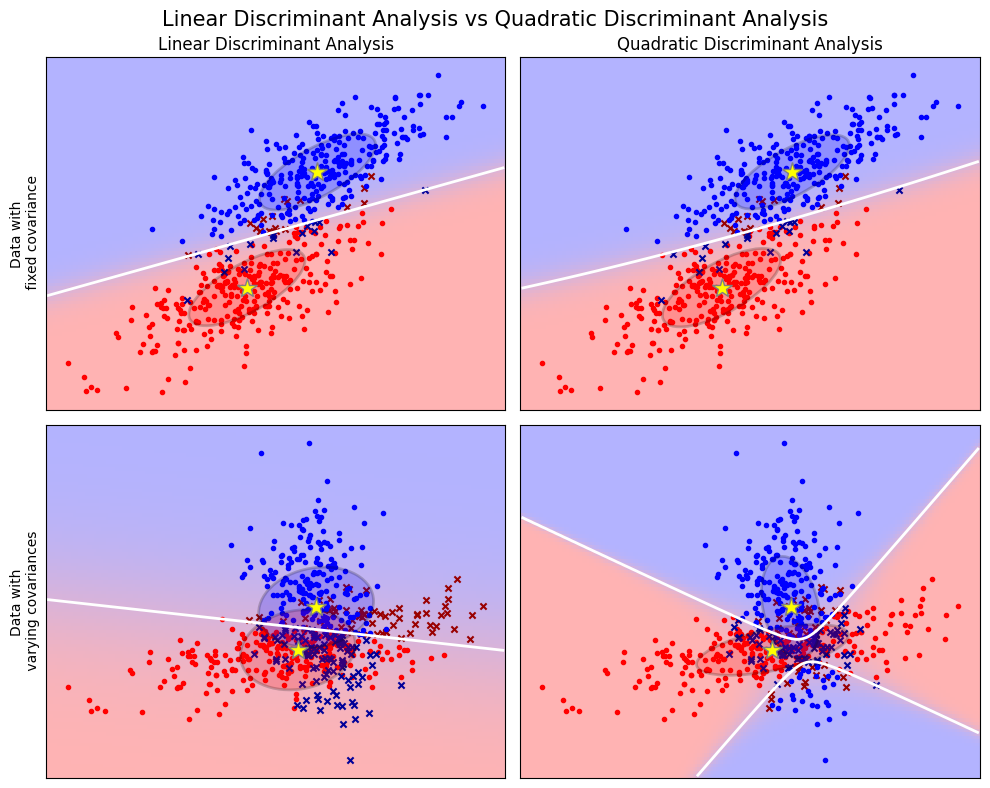

In [20]:
from scipy import linalg
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib import colors

from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis

# #############################################################################
# Colormap
cmap = colors.LinearSegmentedColormap(
    'red_blue_classes',
    {'red': [(0, 1, 1), (1, 0.7, 0.7)],
     'green': [(0, 0.7, 0.7), (1, 0.7, 0.7)],
     'blue': [(0, 0.7, 0.7), (1, 1, 1)]})

# 兼容新旧 Matplotlib，并避免重复注册报错
try:
    if 'red_blue_classes' not in mpl.colormaps:
        mpl.colormaps.register(cmap=cmap)
except AttributeError:
    # 旧版 Matplotlib 回退
    try:
        plt.cm.register_cmap(cmap=cmap)
    except ValueError:
        pass


# #############################################################################
# Generate datasets
def dataset_fixed_cov():
    '''Generate 2 Gaussians samples with the same covariance matrix'''
    n, dim = 300, 2
    np.random.seed(0)
    C = np.array([[0., -0.23], [0.83, .23]])
    X = np.r_[np.dot(np.random.randn(n, dim), C),
              np.dot(np.random.randn(n, dim), C) + np.array([1, 1])]
    y = np.hstack((np.zeros(n), np.ones(n)))
    return X, y


def dataset_cov():
    '''Generate 2 Gaussians samples with different covariance matrices'''
    n, dim = 300, 2
    np.random.seed(0)
    C = np.array([[0., -1.], [2.5, .7]]) * 2.
    X = np.r_[np.dot(np.random.randn(n, dim), C),
              np.dot(np.random.randn(n, dim), C.T) + np.array([1, 4])]
    y = np.hstack((np.zeros(n), np.ones(n)))
    return X, y


# #############################################################################
# Plot functions
def plot_data(lda, X, y, y_pred, fig_index):
    splot = plt.subplot(2, 2, fig_index)
    if fig_index == 1:
        plt.title('Linear Discriminant Analysis')
        plt.ylabel('Data with\n fixed covariance')
    elif fig_index == 2:
        plt.title('Quadratic Discriminant Analysis')
    elif fig_index == 3:
        plt.ylabel('Data with\n varying covariances')

    tp = (y == y_pred)  # True Positive
    tp0, tp1 = tp[y == 0], tp[y == 1]
    X0, X1 = X[y == 0], X[y == 1]
    X0_tp, X0_fp = X0[tp0], X0[~tp0]
    X1_tp, X1_fp = X1[tp1], X1[~tp1]

    # class 0: dots
    plt.scatter(X0_tp[:, 0], X0_tp[:, 1], marker='.', color='red')
    plt.scatter(X0_fp[:, 0], X0_fp[:, 1], marker='x',
                s=20, color='#990000')  # dark red

    # class 1: dots
    plt.scatter(X1_tp[:, 0], X1_tp[:, 1], marker='.', color='blue')
    plt.scatter(X1_fp[:, 0], X1_fp[:, 1], marker='x',
                s=20, color='#000099')  # dark blue

    # class 0 and 1 : areas
    nx, ny = 200, 100
    x_min, x_max = plt.xlim()
    y_min, y_max = plt.ylim()
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, nx),
                         np.linspace(y_min, y_max, ny))
    Z = lda.predict_proba(np.c_[xx.ravel(), yy.ravel()])
    Z = Z[:, 1].reshape(xx.shape)
    plt.pcolormesh(xx, yy, Z, cmap='red_blue_classes',
                   norm=colors.Normalize(0., 1.), zorder=0)
    plt.contour(xx, yy, Z, [0.5], linewidths=2., colors='white')

    # means
    plt.plot(lda.means_[0][0], lda.means_[0][1],
             '*', color='yellow', markersize=15, markeredgecolor='grey')
    plt.plot(lda.means_[1][0], lda.means_[1][1],
             '*', color='yellow', markersize=15, markeredgecolor='grey')

    return splot


def plot_ellipse(splot, mean, cov, color):
    v, w = linalg.eigh(cov)
    u = w[0] / linalg.norm(w[0])
    angle = np.arctan(u[1] / u[0])
    angle = 180 * angle / np.pi  # convert to degrees
    # filled Gaussian at 2 standard deviation
    # 注意：Matplotlib 3.8+ 中 angle 为仅关键字参数
    ell = mpl.patches.Ellipse(
        xy=mean,
        width=2 * v[0] ** 0.5,
        height=2 * v[1] ** 0.5,
        angle=180 + angle,
        facecolor=color,
        edgecolor='black',
        linewidth=2,
    )
    ell.set_clip_box(splot.bbox)
    ell.set_alpha(0.2)
    splot.add_artist(ell)
    splot.set_xticks(())
    splot.set_yticks(())


def plot_lda_cov(lda, splot):
    plot_ellipse(splot, lda.means_[0], lda.covariance_, 'red')
    plot_ellipse(splot, lda.means_[1], lda.covariance_, 'blue')


def plot_qda_cov(qda, splot):
    plot_ellipse(splot, qda.means_[0], qda.covariance_[0], 'red')
    plot_ellipse(splot, qda.means_[1], qda.covariance_[1], 'blue')


plt.figure(figsize=(10, 8), facecolor='white')
plt.suptitle('Linear Discriminant Analysis vs Quadratic Discriminant Analysis',
             y=0.98, fontsize=15)
for i, (X, y) in enumerate([dataset_fixed_cov(), dataset_cov()]):
    # Linear Discriminant Analysis
    lda = LinearDiscriminantAnalysis(solver="svd", store_covariance=True)
    y_pred = lda.fit(X, y).predict(X)
    splot = plot_data(lda, X, y, y_pred, fig_index=2 * i + 1)
    plot_lda_cov(lda, splot)
    plt.axis('tight')

    # Quadratic Discriminant Analysis
    qda = QuadraticDiscriminantAnalysis(store_covariance=True)
    y_pred = qda.fit(X, y).predict(X)
    splot = plot_data(qda, X, y, y_pred, fig_index=2 * i + 2)
    plot_qda_cov(qda, splot)
    plt.axis('tight')
plt.tight_layout()
plt.subplots_adjust(top=0.92)
plt.show()

## 5. 小结

本次实验介绍了Fisher线性判别分析的思路和一般步骤，并且通过一个实例使用sklearn库实现LDA判别分析。

通过本次实验需要掌握以下内容：
- 掌握Fisher线性判别分析的思路
- 掌握Fisher线性判别分析的一般步骤
- 掌握基于sklearn实现LDA判别分析